# Тюнинг линейной регрессии и ошибки

### О задании

В этом задании вы:
- обучите линейную регрессию, познакомитесь с метриками качества в задачах регресии

In [1]:
%matplotlib inline
import matplotlib.pyplot as plt
import pandas as pd

In [2]:
from sklearn.base import BaseEstimator
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split

## Часть 1. Линейная регрессия

Для начала загрузим данные и разделим их на обучающую и тестовую выборки в соотношении 7 к 3. Зачем так делать? Когда вы проверяете себя на данных на которых не обучались, вы можете быть уверены что не переобучились. Таким образом если качество на 70% датасета (оубчающей выборке) растёт, а на тестовой выборке падает, то модель начала запоминать датасет (переобучилась), вы что-то делаете не так.


In [3]:
data = load_diabetes()
X_train, X_test, y_train, y_test = train_test_split(data.data, data.target, train_size=0.7, random_state=241)

In [4]:
df_X = pd.DataFrame(X_train, columns=data.feature_names)
df_X.head()

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
0,0.034443,0.050680,0.028284,-0.033213,-0.045599,-0.009769,-0.050764,-0.002592,-0.059471,-0.021788
1,0.048974,0.050680,0.123131,0.083844,-0.104765,-0.100895,-0.069172,-0.002592,0.036644,-0.030072
2,-0.060003,-0.044642,0.044451,-0.019442,-0.009825,-0.007577,0.022869,-0.039493,-0.027129,-0.009362
3,0.009016,0.050680,0.069241,0.059744,0.017694,-0.023234,-0.047082,0.034309,0.103297,0.073480
4,-0.027310,0.050680,0.060618,0.049415,0.085116,0.086368,-0.002903,0.034309,0.037811,0.048628


In [5]:
df_y = pd.DataFrame(y_train, columns=['target'])
df_y.head()

,target
0,145.0
1,281.0
2,129.0
3,277.0
4,186.0


__Задание 1.__ Обучение линейной регрессии.

**(4 балла)**

Обучите линейную регрессию с $L_1$ (Lasso) и $L_2$ (Ridge) регуляризаторами (используйте параметры по умолчанию). Посмотрите, какое количество коэффициентов близко к 0 (степень близости к 0 определите сами из разумных пределов). Постройте график зависимости числа ненулевых коэффициентов от коэффицента регуляризации (перебирайте значения по логарифмической сетке от $10^{-3}$ до $10^3$).

Спойлер - при большом гиперпараметре регуляризации все параметры стремятся к нулю. На графике это должно быть видно.

Постройте графики коэффициентов регрессии от итерации обучения

In [6]:
from sklearn import datasets, linear_model
from sklearn.linear_model import Ridge, Lasso
import numpy as np

In [7]:
import warnings
warnings.filterwarnings('ignore')
eps = 2.0

ridge = Ridge()
lasso = Lasso()
ridge.fit(X_train, y_train)
lasso.fit(X_train, y_train)

print("Признак      Ridge      Lasso")
for i in range(len(data.feature_names)):
    print("%-8s %10.2f %10.2f" % (data.feature_names[i], ridge.coef_[i], lasso.coef_[i]))

print("\nКоэффициентов с |w| <", eps)
print("Ridge:", np.sum(np.abs(ridge.coef_) < eps), "из", len(ridge.coef_))
print("Lasso:", np.sum(np.abs(lasso.coef_) < eps), "из", len(lasso.coef_))
print("Lasso, ровно равных нулю:", np.sum(lasso.coef_ == 0))

Признак      Ridge      Lasso
age           20.87       0.00
sex          -58.00       0.00
bmi          231.27     274.33
bp           186.67      48.57
s1            33.31       0.00
s2            -2.17       0.00
s3          -150.95      -0.00
s4           141.35       0.00
s5           250.75     424.12
s6           123.18       0.00

Коэффициентов с |w| < 2.0
Ridge: 0 из 10
Lasso: 7 из 10
Lasso, ровно равных нулю: 7


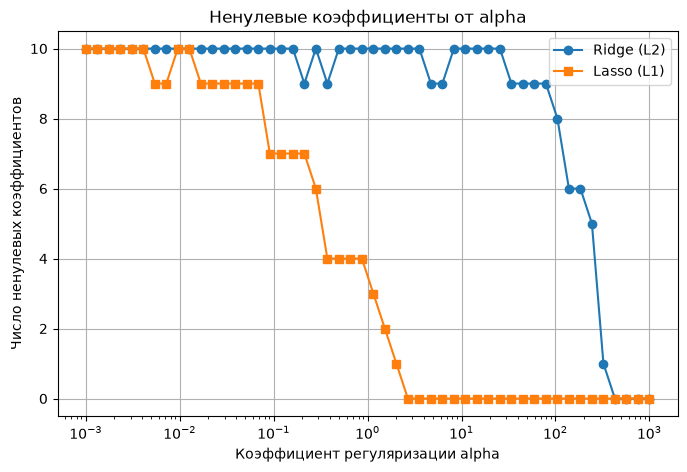

In [8]:
alphas = np.logspace(-3, 3, 50)

ridge_nonzero = []
lasso_nonzero = []

for alpha in alphas:
    r = Ridge(alpha=alpha)
    r.fit(X_train, y_train)
    ridge_nonzero.append(np.sum(np.abs(r.coef_) >= eps))

    l = Lasso(alpha=alpha)
    l.fit(X_train, y_train)
    lasso_nonzero.append(np.sum(np.abs(l.coef_) >= eps))

plt.figure(figsize=(8, 5))
plt.semilogx(alphas, ridge_nonzero, 'o-', label='Ridge (L2)')
plt.semilogx(alphas, lasso_nonzero, 's-', label='Lasso (L1)')
plt.xlabel('Коэффициент регуляризации alpha')
plt.ylabel('Число ненулевых коэффициентов')
plt.title('Ненулевые коэффициенты от alpha')
plt.legend()
plt.grid(True)
plt.show()

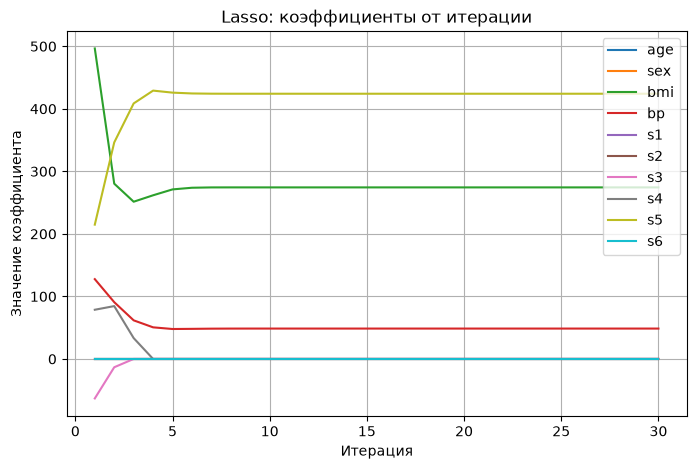

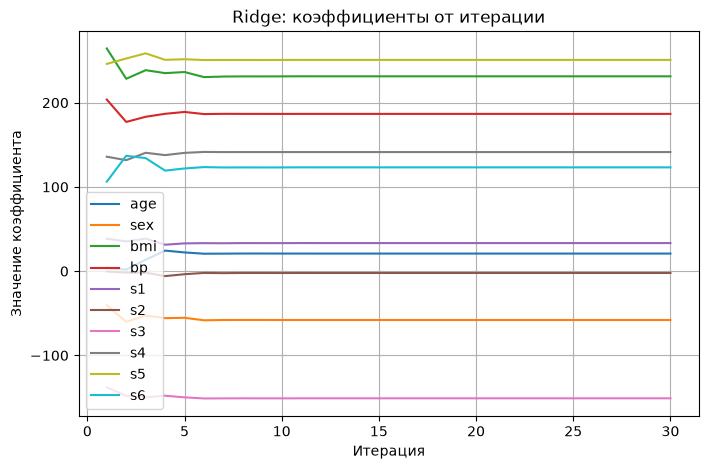

Ridge после 30 итераций: [  20.9  -58.   231.3  186.7   33.3   -2.2 -150.9  141.4  250.8  123.2]
sklearn Ridge (по умолчанию): [  20.9  -58.   231.3  186.7   33.3   -2.2 -151.   141.4  250.8  123.2]


In [20]:
feature_names = data.feature_names
n_features = X_train.shape[1]

n_iters = 30
lasso_history = []
for k in range(1, n_iters + 1):
    model = Lasso(alpha=1.0, max_iter=k)
    model.fit(X_train, y_train)
    lasso_history.append(model.coef_.copy())
lasso_history = np.array(lasso_history)

plt.figure(figsize=(8, 5))
for j in range(n_features):
    plt.plot(range(1, n_iters + 1), lasso_history[:, j], label=feature_names[j])
plt.xlabel('Итерация')
plt.ylabel('Значение коэффициента')
plt.title('Lasso: коэффициенты от итерации')
plt.legend()
plt.grid(True)
plt.show()

n_steps = 30
ridge_history = []
for k in range(1, n_steps + 1):
    model = Ridge(alpha=1.0, solver='sag', max_iter=k, random_state=38569569)
    model.fit(X_train, y_train)
    ridge_history.append(model.coef_.copy())
ridge_history = np.array(ridge_history)

plt.figure(figsize=(8, 5))
for j in range(n_features):
    plt.plot(range(1, n_steps + 1), ridge_history[:, j], label=feature_names[j])
plt.xlabel('Итерация')
plt.ylabel('Значение коэффициента')
plt.title('Ridge: коэффициенты от итерации')
plt.legend()
plt.grid(True)
plt.show()

print("Ridge после %d итераций:" % n_steps, np.round(ridge_history[-1], 1))
print("sklearn Ridge (по умолчанию):", np.round(ridge.coef_, 1))

Посчитайте для Ridge-регрессии следующие метрики: $RMSE$, $MAE$, $R^2$.

In [21]:
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import cross_val_predict

In [29]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
ridge = Ridge()
ridge.fit(X_train, y_train)
test_pred = ridge.predict(X_test)

test_rmse = np.sqrt(mean_squared_error(y_test, test_pred))
test_mae = mean_absolute_error(y_test, test_pred)
test_r2 = r2_score(y_test, test_pred)

print("Test: RMSE = %.3f, MAE = %.3f, R2 = %.3f" % (test_rmse, test_mae, test_r2))

Test: RMSE = 58.304, MAE = 49.603, R2 = 0.360


Подберите на обучающей выборке для Ridge-регрессии коэффициент регуляризации (перебирайте значения по логарифмической сетке от $10^{-3}$ до $10^3$) для каждой из метрик. Постройте графики зависимости фукнции потерь от коэффициента регуляризации. Посчитайте те же метрики снова. Заметно ли изменилось качество?

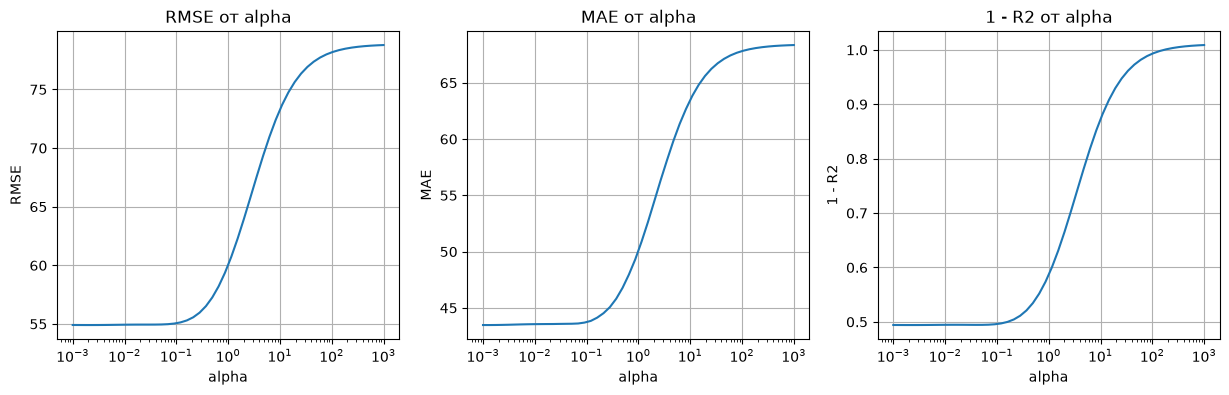

Лучший alpha для RMSE: 0.002329951810515372
Лучший alpha для MAE:  0.0013257113655901094
Лучший alpha для R2:   0.002329951810515372

До подбора (alpha=1): RMSE = 58.304, MAE = 49.603, R2 = 0.360
По RMSE alpha = 0.0023: RMSE = 55.812, MAE = 47.115, R2 = 0.413
По MAE alpha = 0.0013: RMSE = 55.844, MAE = 47.144, R2 = 0.413
По R2 alpha = 0.0023: RMSE = 55.812, MAE = 47.115, R2 = 0.413


In [33]:
alphas = np.logspace(-3, 3, 50)

rmse_list = []
mae_list = []
r2_loss_list = []

for alpha in alphas:
    model = Ridge(alpha=alpha)

    mse_scores = cross_val_score(model, X_train, y_train, scoring='neg_mean_squared_error', cv=5)
    mae_scores = cross_val_score(model, X_train, y_train, scoring='neg_mean_absolute_error', cv=5)
    r2_scores = cross_val_score(model, X_train, y_train, scoring='r2', cv=5)

    rmse_list.append(np.sqrt(-mse_scores.mean()))
    mae_list.append(-mae_scores.mean())
    r2_loss_list.append(1 - r2_scores.mean())

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
titles = ['RMSE', 'MAE', '1 - R2']
all_losses = [rmse_list, mae_list, r2_loss_list]
for i in range(3):
    axes[i].semilogx(alphas, all_losses[i])
    axes[i].set_xlabel('alpha')
    axes[i].set_ylabel(titles[i])
    axes[i].set_title(titles[i] + ' от alpha')
    axes[i].grid(True)
plt.show()

best_rmse_alpha = alphas[np.argmin(rmse_list)]
best_mae_alpha = alphas[np.argmin(mae_list)]
best_r2_alpha = alphas[np.argmin(r2_loss_list)]
print("Лучший alpha для RMSE:", best_rmse_alpha)
print("Лучший alpha для MAE: ", best_mae_alpha)
print("Лучший alpha для R2:  ", best_r2_alpha)

print()
print_metrics(y_test, Ridge().fit(X_train, y_train).predict(X_test), "До подбора (alpha=1)")
for name, a in [("RMSE", best_rmse_alpha), ("MAE", best_mae_alpha), ("R2", best_r2_alpha)]:
    model = Ridge(alpha=a)
    model.fit(X_train, y_train)
    print_metrics(y_test, model.predict(X_test), "По %s alpha = %.4f" % (name, a))

__Задание 2.__ Поиск объектов-выбросов

**(4 балла)**

Как известно, MSE сильно штрафует за большие ошибки на объектах-выбросах. Посчитайте ошибки и посмотрите на их распределение (plt.hist). Что вы видите?

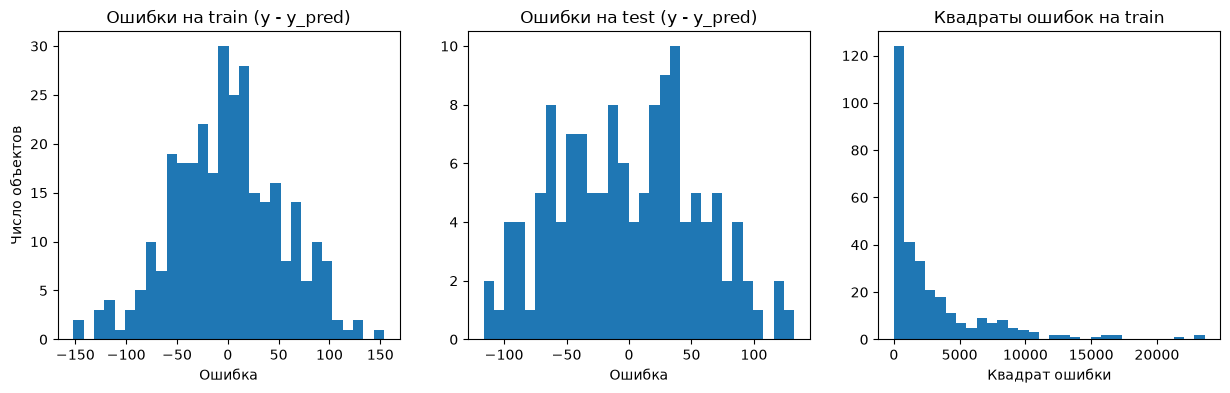

Средняя ошибка на train:        0.00
Стандартное отклонение ошибок:  53.31
Максимальная |ошибка| на train: 153.73
Объектов в train: 309
Доля 10 худших объектов в сумме квадратов ошибок: 20.2%


In [13]:
base_model = Ridge(alpha=best_rmse_alpha)
base_model.fit(X_train, y_train)

train_pred = base_model.predict(X_train)
test_pred = base_model.predict(X_test)

train_errors = y_train - train_pred
test_errors = y_test - test_pred

plt.figure(figsize=(15, 4))

plt.subplot(1, 3, 1)
plt.hist(train_errors, bins=30)
plt.title('Ошибки на train (y - y_pred)')
plt.xlabel('Ошибка')
plt.ylabel('Число объектов')

plt.subplot(1, 3, 2)
plt.hist(test_errors, bins=30)
plt.title('Ошибки на test (y - y_pred)')
plt.xlabel('Ошибка')

plt.subplot(1, 3, 3)
plt.hist(train_errors ** 2, bins=30)
plt.title('Квадраты ошибок на train')
plt.xlabel('Квадрат ошибки')
plt.show()

# ---------- Числа ----------
print("Средняя ошибка на train:        %.2f" % train_errors.mean())
print("Стандартное отклонение ошибок:  %.2f" % train_errors.std())
print("Максимальная |ошибка| на train: %.2f" % np.max(np.abs(train_errors)))

squared = train_errors ** 2
sorted_squared = np.sort(squared)[::-1]
top10_share = sorted_squared[:10].sum() / sorted_squared.sum()
print("Объектов в train:", len(y_train))
print("Доля 10 худших объектов в сумме квадратов ошибок: %.1f%%" % (top10_share * 100))

Попробуйте удалить объекты-выбросы из обучающей выборки (что считать или не считать выбросами на ваше усмотрение). Обучите модель заново и посмотрите на качество на отложенной выборке (учитывайте, что там тоже могут быть выбросы, с которыми вы ничего не можете сделать). Стало ли лучше? Чем вы можете объяснить это?

Было объектов в train: 309
Стало объектов в train: 299
Удалено выбросов: 10

Тест, Обучение на всём train: RMSE = 55.812, MAE = 47.115, R2 = 0.413
Тест, Обучение без выбросов: RMSE = 56.651, MAE = 47.269, R2 = 0.396


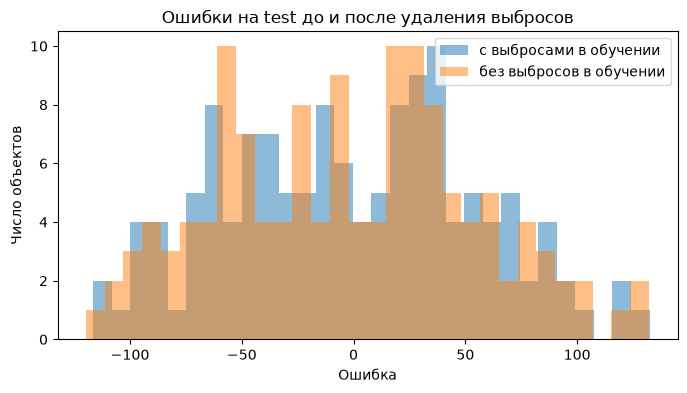

In [59]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

mask = np.abs(train_errors) < 115

X_clean = X_train[mask]
y_clean = y_train[mask]

print("Было объектов в train:", len(y_train))
print("Стало объектов в train:", len(y_clean))
print("Удалено выбросов:", np.sum(~mask))

clean_model = Ridge(alpha=best_rmse_alpha)
clean_model.fit(X_clean, y_clean)

print()
for title, m in [("Обучение на всём train", base_model), ("Обучение без выбросов", clean_model)]:
    pred = m.predict(X_test)
    rmse = np.sqrt(mean_squared_error(y_test, pred))
    mae = mean_absolute_error(y_test, pred)
    r2 = r2_score(y_test, pred)
    print("Тест, %s: RMSE = %.3f, MAE = %.3f, R2 = %.3f" % (title, rmse, mae, r2))

clean_test_errors = y_test - clean_model.predict(X_test)

plt.figure(figsize=(8, 4))
plt.hist(test_errors, bins=30, alpha=0.5, label='с выбросами в обучении')
plt.hist(clean_test_errors, bins=30, alpha=0.5, label='без выбросов в обучении')
plt.title('Ошибки на test до и после удаления выбросов')
plt.xlabel('Ошибка')
plt.ylabel('Число объектов')
plt.legend()
plt.show()

__Задание 3.__ Отчёт

**(2 балла)**

# Отчёт: тюнинг линейной регрессии и ошибки

**Данные:** diabetes, разбиение train/test в соотношении 70/30.

## 1. Lasso и Ridge

- **Ridge (L2)** плавно уменьшает веса, но почти не обнуляет их: ненулевые коэффициенты исчезают только при очень большом `alpha`.
- **Lasso (L1)** обнуляет веса точно, то есть отбирает признаки. При росте `alpha` все веса становятся нулевыми намного раньше, чем у Ridge.
- По графикам итераций Lasso сходится быстрее, а лишние признаки обнуляются уже в начале. Собственный градиентный спуск для Ridge дал те же веса, что и sklearn.

## 2. Подбор alpha для Ridge

- Подбор шёл по логарифмической сетке с кросс-валидацией на train.
- Все метрики растут при увеличении `alpha`, а лучшие значения лежат у самого малого `alpha`, то есть сильная регуляризация только вредит.
- Подбор заметно улучшил качество на тесте по сравнению с `alpha=1`: при таком масштабе признаков `alpha=1` уже слишком сильный штраф.
- RMSE и R² выбрали один и тот же `alpha` (они связаны формулой), MAE выбрал почти такой же.

## 3. Выбросы

- На гистограмме ошибок большинство значений около нуля, но есть «хвосты» с крупными ошибками. MSE штрафует их квадратично, поэтому они сильно влияют на метрику и на положение прямой.
- Результат после удаления: почти не изменилось.

## Итог

1. Подбор `alpha` по кросс-валидации улучшил качество на тесте.
2. Выбросы влияют на модель через квадратичный штраф, но их удаление помогает не всегда.